In [49]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yashbhattme/predictive-maintainance/ai4i2020.csv


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [51]:
data = pd.read_csv("/kaggle/input/datasets/yashbhattme/predictive-maintainance/ai4i2020.csv")
df = pd.DataFrame(data)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [52]:
df.shape

(10000, 14)

In [53]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [57]:
df["Tool wear [min]"].value_counts()

Tool wear [min]
0      120
2       69
5       63
7       58
59      58
      ... 
237      1
239      1
241      1
251      1
253      1
Name: count, Length: 246, dtype: int64

In [58]:
# CONCLUSION The target variable Machine failure is highly imbalanced, with only 3.39% of observations representing machine failures. SHAPE IS 10K,14. NO NULL VALUES AND NO DUPLICATE VALUES ,  machinefailure is target columns . twf,hdf,pwf,osf,rnf should e oject

# EDA

In [59]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [60]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

# numerical univariate

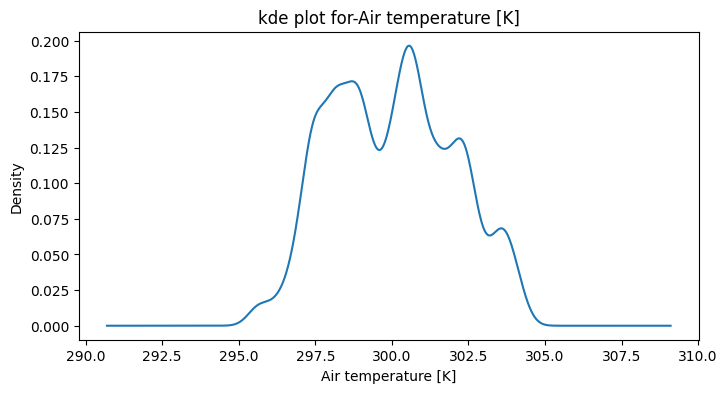

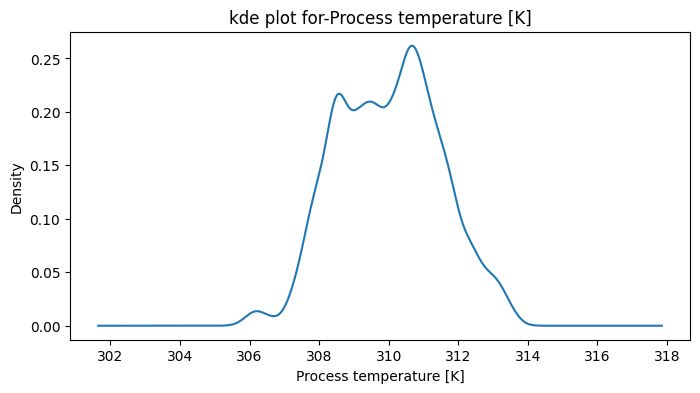

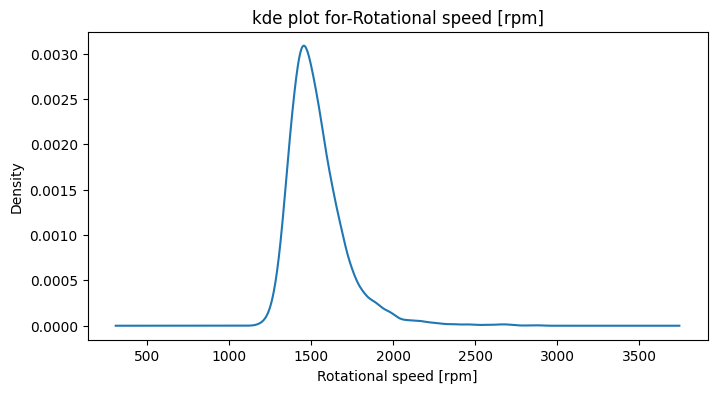

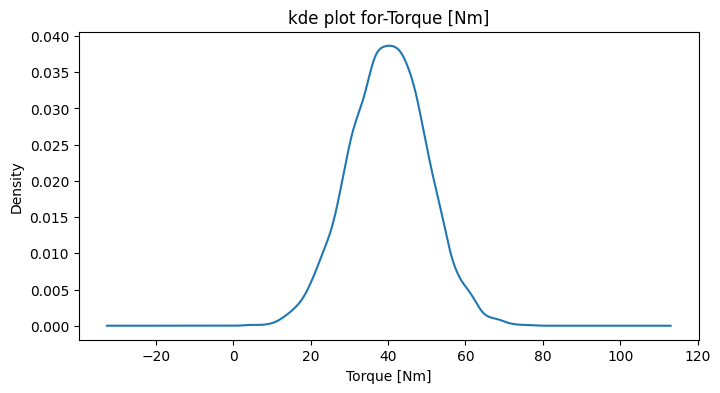

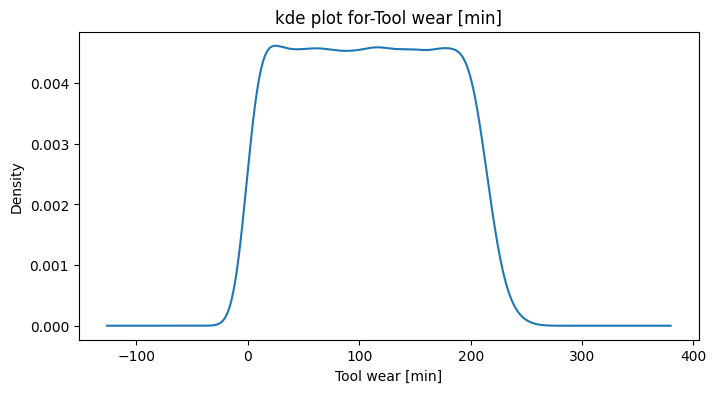

In [61]:
# univariate analysis - numerical
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].plot(kind="kde")
    plt.title(f"kde plot for-{col}")
    plt.xlabel(col)
    plt.show()

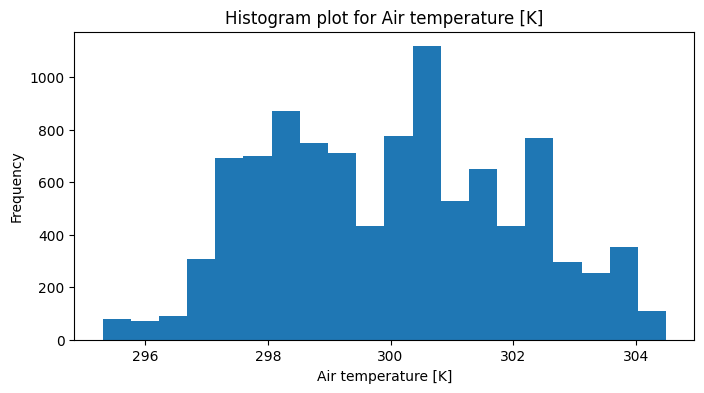

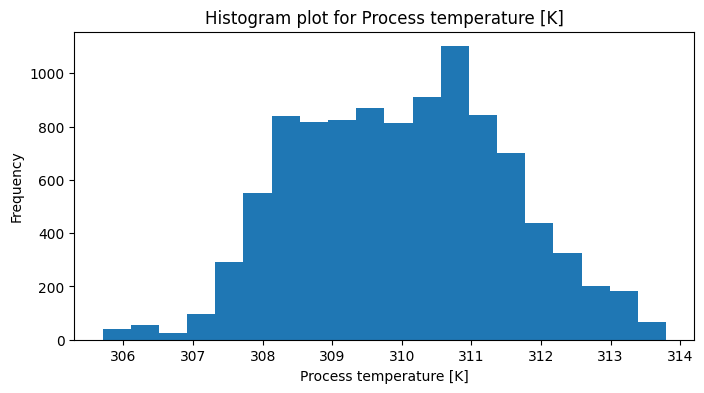

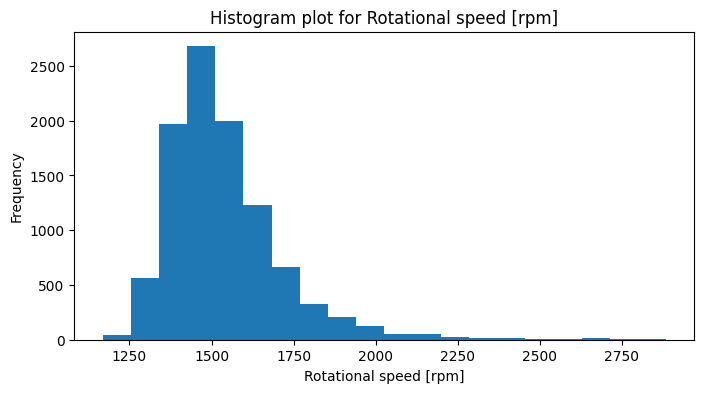

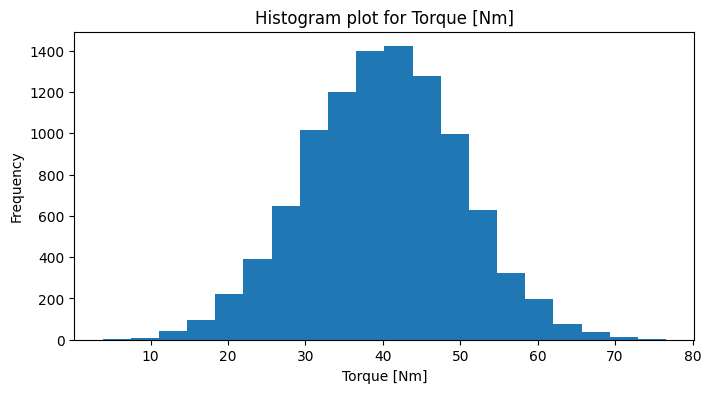

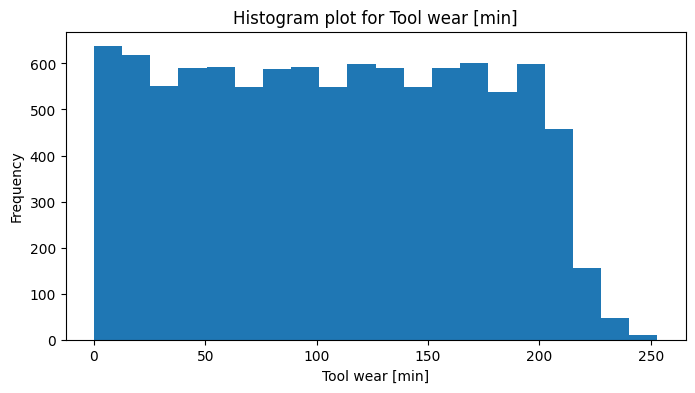

In [62]:
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].plot(kind="hist",bins=20)
    plt.xlabel(col)
    plt.title(f"Histogram plot for {col}")
    plt.show()
    

In [63]:
# tool wear right skewed very slight , 0 to 10 peak , data is not concentrated at one place thus spread is low. torque 40 to 43 peak normal distriution slight left skewed.rotation speed is highly right skewed.approx 1500rpm is peak.process temperature 310.6 to 311k peak high spread 4 peaks quadmodal left skewed. air temp high spread 4 peak quadmodal 300.2 to 300.4 longest peak left skewed

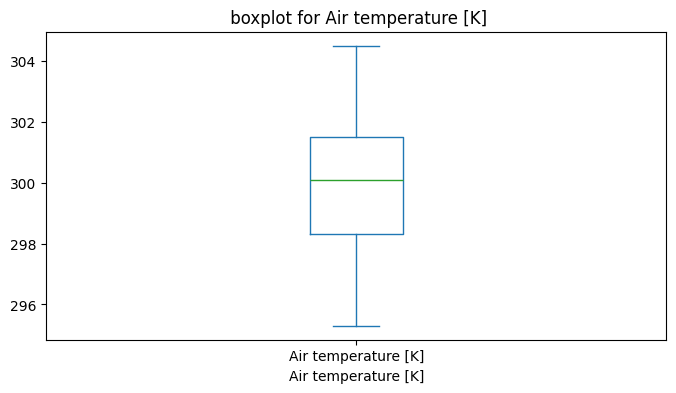

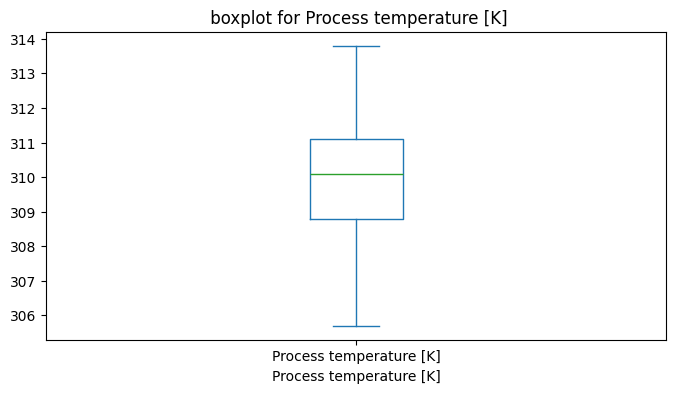

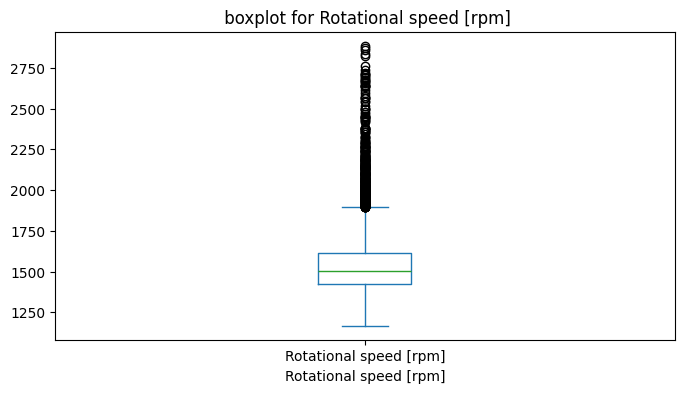

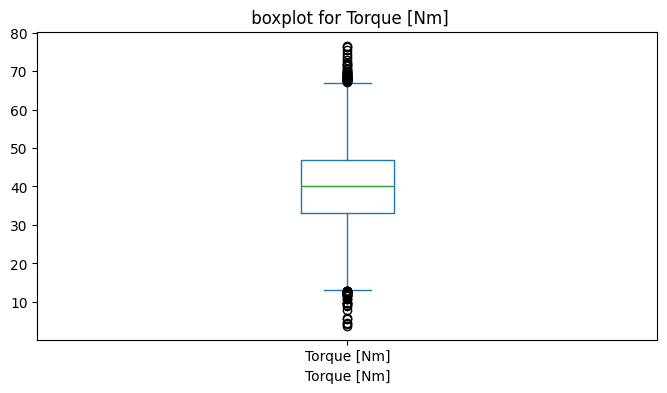

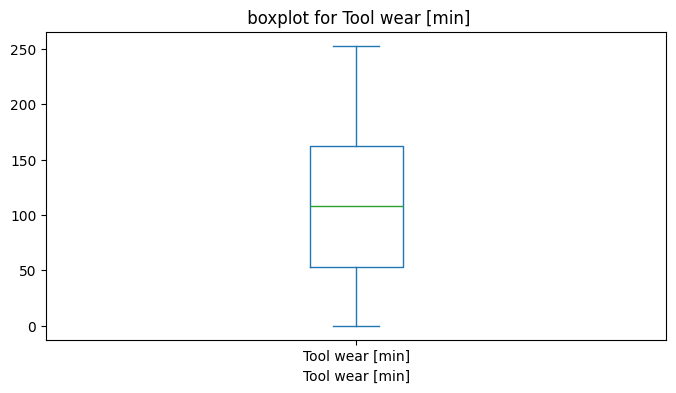

In [64]:
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].plot(kind="box")
    plt.xlabel(col)
    plt.title(f" boxplot for {col}")
    plt.show()
    

In [65]:
# zero outliers in tool wear , process temperature , air temperature , rpm has many outliers aove its max value tho it is not confirmed. torque also has outliers oth aove max value and min value ut needs to investigate further

In [66]:
df["HDF"].value_counts()

HDF
0    9885
1     115
Name: count, dtype: int64

In [67]:
# from sklearn.preprocessing import LabelEncoder
# cols = ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
#        'RNF'] 
# le = LabelEncoder()
# df[cols] = le.fit_transform(cols)

In [70]:
cols = ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'] 
for col in cols:
    df[col] = df[col].astype(str)

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  object 
 9   TWF                      10000 non-null  object 
 10  HDF                      10000 non-null  object 
 11  PWF                      10000 non-null  object 
 12  OSF                      10000 non-null  object 
 13  RNF                      10000 non-null  object 
dtypes: float64(3), int64(3)

# categorical univariate

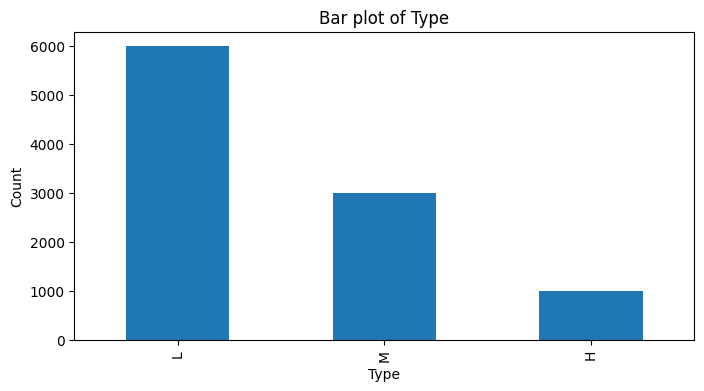

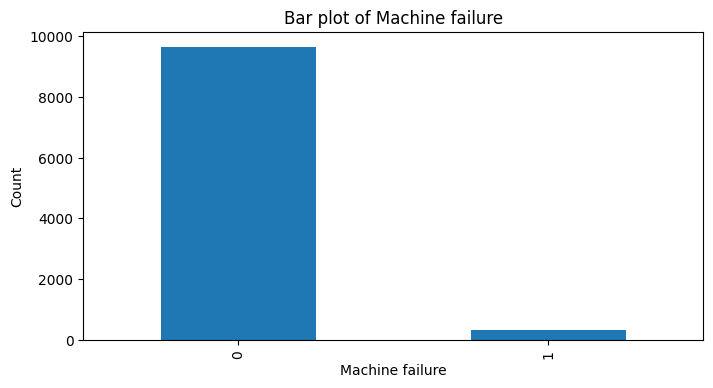

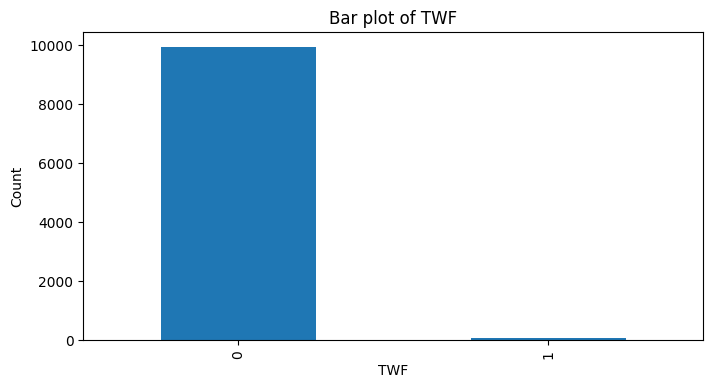

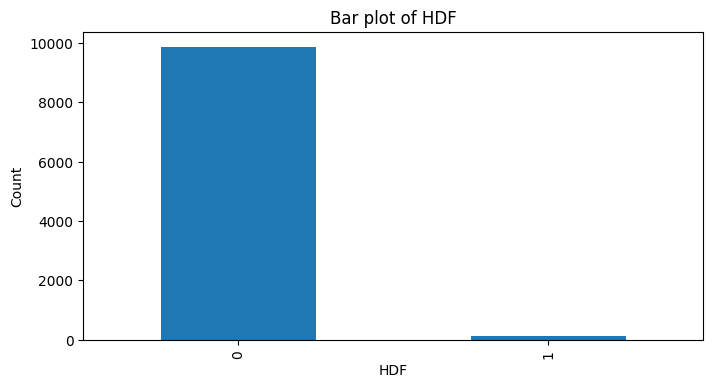

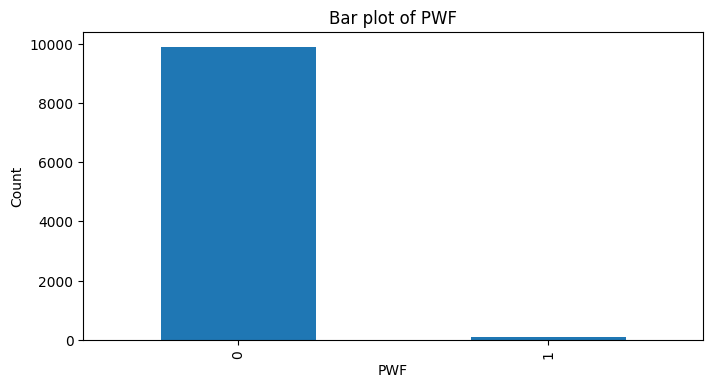

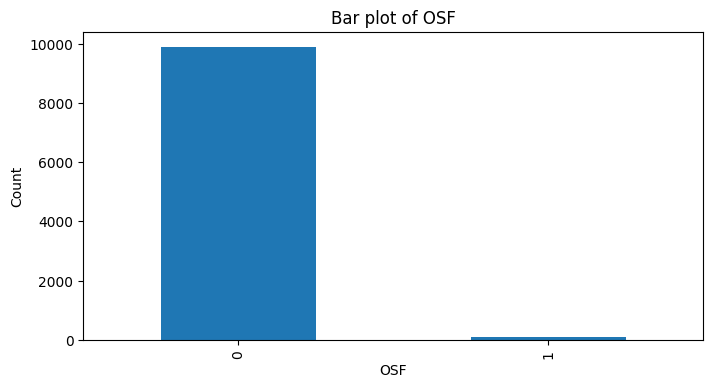

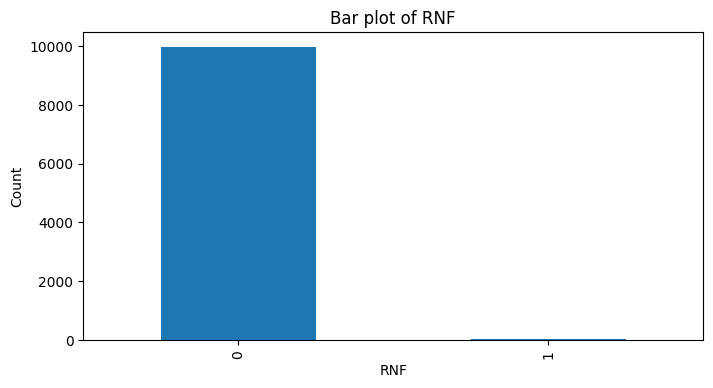

In [74]:
# univariate analysis - categorical columns
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind='bar')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"Bar plot of {col}")
    plt.show()



In [ ]:
# overall bar of rnf,twf,osf,pwf,hdf,machine failure are highly imlanced columns with maximum counts at machine did not fail. and in type L is around 6000 ,  M id around 3000 and H is around 1000 

# conclusion-I

**Univariate Analysis Conclusion

The numerical features show different distributions. Tool wear is slightly right-skewed, while rotational speed is highly right-skewed. Torque is approximately normally distributed with slight left skewness. Air temperature and process temperature show multimodal distributions with relatively high spread. Potential outliers were observed mainly in rotational speed and torque, which require further investigation.

The categorical analysis shows that Type L is the most common category, followed by Type M and Type H. The binary failure-related variables are highly imbalanced, with the majority of observations having a value of 0 (no failure). The target variable Machine failure is also highly imbalanced, with only a small percentage of machines experiencing failure.**

# numerical bivariate

In [76]:
df.describe()
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

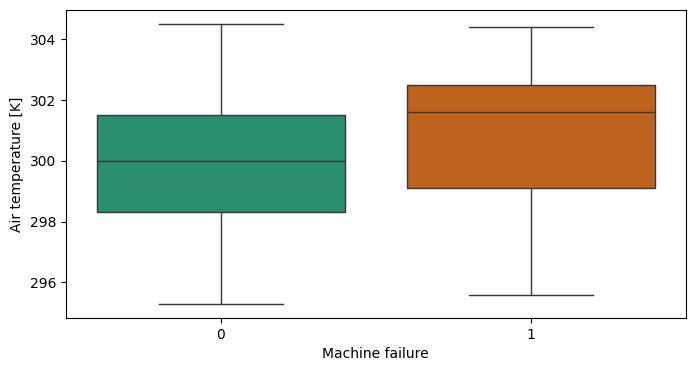

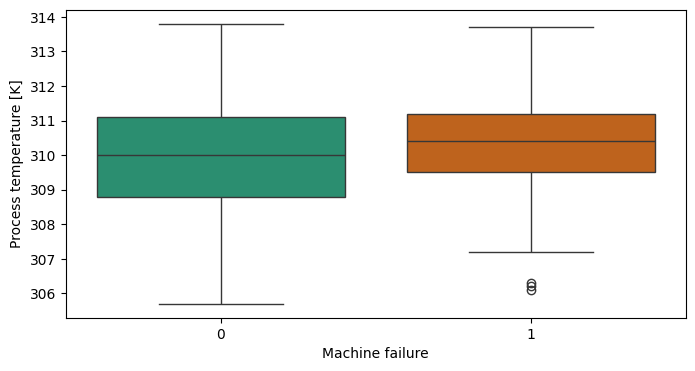

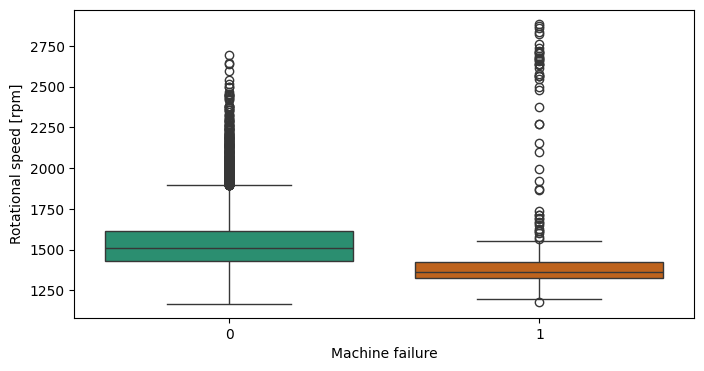

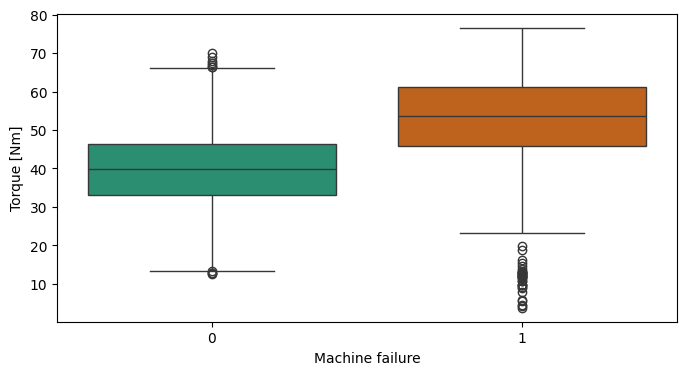

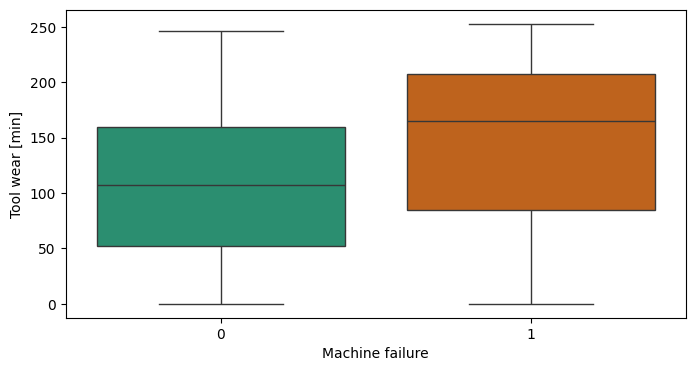

In [83]:
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x="Machine failure" , y=col,data=df,palette = "Dark2")
    plt.show()

In [ ]:
total wear v machine failure , machine failure 0s and 1s median are very different where 1s has more median. inside the 1s box median is not at perfectly centered more aligned towards 75%, 1s IQR overall more than 0s. failures appeared to directly proportional to tool wear. torque v machine failure 0s and 1s median has much difference and 1s has higher median 1s also has more outliers at min side here while 0s has less outliers that 1s ut in oth max and min side. spread is nearly same and it appears that torque also directly prop to mach failure.machine v rotation speed here rotation is inverse prop to failure,1s spread is very low . oth 0s and 1s median are not same , median of 1s is low. oth 0s and 1s has outliers.